<h1><U>Analysis of Cold Chain Infrastructure Availability and Component Capacity in India</U> </H1>

<H2> 1. <U>Introduction</U> </H2>

In this project, I analyse cold chain infrastructure records from different states and districts in India. The dataset contains information about projects, subsidy years, agencies, beneficiaries, infrastructure components, units and capacity. I will follow a structured approach starting from data loading, then data cleaning and preprocessing, followed by exploratory data analysis (EDA), visualizations, and finally insight generation.

Before starting any data analysis project, I first import the required Python libraries. These libraries provide the tools needed for data handling, numerical computation, and visualization.

Pandas is used to load and manipulate tabular data.

NumPy is used for numerical operations.

Matplotlib and Seaborn are used to create visualizations.


<h2> 2.<U>Problem Statement</U></h2>

The purpose of this analysis is to understand how cold chain infrastructure projects and their components are distributed across India. I also examine project status, participating agencies, subsidy years and recorded capacity.


<h2>3.<U>Objectives</U></h2>

1.Understand the structure and quality of the dataset.


2.Clean missing values and check duplicate records

3.Study the distribution of projects across states and districts.

4.Analyse project status, agencies, subsidy years and component categories.

5.Compare capacity only within the same capacity unit.

6.Present findings through visualisations and statistical summaries.

<h3>I start by importing the Python libraries (Pandas ,NumPy , Matplotlib and Seaborn) required for data loading, cleaning, analysis and visualisation.</h3>

In [176]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

<h3> The dataset file integrated-cold-chain-availability-component-details.csv is stored in the same folder as this Jupyter Notebook. Because of this, I can load the dataset directly by providing only the file name, without using an absolute file path.I load the dataset into a Pandas DataFrame named df.</h3>

In [177]:
df = pd.read_csv("integrated-cold-chain-availability-component-details.csv")

<h3>The output displays the first five rows. I use this to confirm that the file has loaded and to understand how the records and column names are organised.</h3>

In [178]:
df.head()

,id,project_code,year_of_subsidy_sanct,state_name,state_code,district_name,district_code,agency,supported_by,beneficiary_name,project_address,current_status,component_category,component,units,capacity,capacity_unit
0,25,2012-HP-02-5,2012-13,Himachal Pradesh,2,Mandi,22,APEDA,NaN,HPMC,"Nigam Vihar, Shima",Completed,Cold / CA Storage,CA Storage,0.0,0.0,MT
1,26,2012-HP-021-5,2012-13,Himachal Pradesh,2,Mandi,22,APEDA,NaN,HPMC,"Nigam Vihar, Shima",Completed,Cold / CA Storage,CA Storage,0.0,0.0,MT
2,784,28AP2002000045,2002-03,Telangana,36,Hyderabad,507,NHB,NHB,Jain Traders,Secundrabad (UP),Completed,Cold / CA Storage,Cold Storage,0.0,375.0,MT
3,97,CC/2018-19/198,2017-18,Arunachal Pradesh,12,Tawang,238,MOFPI,NaN,Gangri Food Products,"Tawang, Arunachal Pradesh",Under Implementation,Cold / CA Storage,Blast Freezer,0.0,2.0,MT
4,99,CC/2018-19/198,2017-18,Arunachal Pradesh,12,Tawang,238,MOFPI,NaN,Gangri Food Products,"Tawang, Arunachal Pradesh",Under Implementation,Cold / CA Storage,Deep Freezer,0.0,1000.0,MT


<h3>The output shows the number of records and columns, followed by each column's data type and non-missing value count. This helps me identify which columns contain text and which contain numeric information.</h3>

In [179]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 5040
Number of columns: 17


In [180]:
print(df.columns)

Index(['id', 'project_code', 'year_of_subsidy_sanct', 'state_name',
       'state_code', 'district_name', 'district_code', 'agency',
       'supported_by', 'beneficiary_name', 'project_address', 'current_status',
       'component_category', 'component', 'units', 'capacity',
       'capacity_unit'],
      dtype='str')


In [181]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5040 entries, 0 to 5039
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id                     5040 non-null   int64  
 1   project_code           5040 non-null   str    
 2   year_of_subsidy_sanct  5040 non-null   str    
 3   state_name             5040 non-null   str    
 4   state_code             5040 non-null   int64  
 5   district_name          5040 non-null   str    
 6   district_code          5040 non-null   int64  
 7   agency                 5040 non-null   str    
 8   supported_by           2959 non-null   str    
 9   beneficiary_name       5039 non-null   str    
 10  project_address        4983 non-null   str    
 11  current_status         5040 non-null   str    
 12  component_category     5040 non-null   str    
 13  component              5040 non-null   str    
 14  units                  4952 non-null   float64
 15  capacity       

<h3>This table provides count, mean, standard deviation, minimum, maximum and quartile values for numeric columns. These statistics help me understand the numerical ranges in the dataset. The id, state codes and district codes are identifiers, so their averages do not have a practical business meaning.</h3>

In [182]:
df.describe()

,id,state_code,district_code,units,capacity
count,5040.000000,5040.000000,5040.000000,4952.000000,5040.000000
mean,2519.500000,14.549802,257.204762,1.714055,3894.400212
std,1455.067009,10.114011,191.781277,5.694312,10933.911661
min,0.000000,1.000000,1.000000,0.000000,0.000000
25%,1259.750000,8.000000,109.000000,0.000000,60.000000
50%,2519.500000,9.000000,166.000000,1.000000,3000.000000
75%,3779.250000,24.000000,458.000000,1.000000,5400.000000
max,5039.000000,37.000000,672.000000,252.000000,400000.000000


<h3>I will now check for missing values and duplicate records before starting the analysis. I have retain the original dataset in df and created a separate working copy called data.</h3>

In [183]:
data = df.copy()


<h3>The output shows how many values are missing in each column. In this dataset, supported_by has many missing values, while a small number of records are missing beneficiary, address, units or capacity-unit information. I review missingness before deciding how to handle it.</h3>

In [184]:
data.isnull().sum()

id                          0
project_code                0
year_of_subsidy_sanct       0
state_name                  0
state_code                  0
district_name               0
district_code               0
agency                      0
supported_by             2081
beneficiary_name            1
project_address            57
current_status              0
component_category          0
component                   0
units                      88
capacity                    0
capacity_unit              70
dtype: int64

<h3>Now i will check the cells for completely duplicated rows and remove them. Removing exact duplicates avoids counting the same complete record more than once. It does not remove records merely because they share a project code, since one project can contain multiple components.</h3>

In [185]:
print("Number of duplicate rows:", data.duplicated().sum())

Number of duplicate rows: 0


<h3> From the above prompt i can see that there are no duplicate rows</h3>

In [186]:
print("Shape after removing duplicates:", data.shape)

Shape after removing duplicates: (5040, 17)


<h3>I used shape code for verifying that the dataset has any changes from that in the dataset in df. However there are no changes. </h3>

<h3>I will now convert the data missing values as percentage and the output below Shows missing values as a percentage of all records. This makes it easier to compare columns with different numbers of missing values and helps me decide whether a column needs special treatment. I made ascending = true so that the values with highest numbers starts from the top.</h3>

In [187]:
missing_percent = (data.isnull().sum() / len(data)) * 100
missing_percent.sort_values(ascending=False)

supported_by             41.289683
units                     1.746032
capacity_unit             1.388889
project_address           1.130952
beneficiary_name          0.019841
id                        0.000000
project_code              0.000000
state_name                0.000000
year_of_subsidy_sanct     0.000000
agency                    0.000000
district_code             0.000000
district_name             0.000000
state_code                0.000000
component_category        0.000000
current_status            0.000000
component                 0.000000
capacity                  0.000000
dtype: float64

<h3>I will now replace missing text values with the label "Not Available" so that records are not lost from categorical analysis. I will leave missing "unit" values unchanged because a missing quantity should not automatically be treated as zero. The below printed result confirm the missing-value handling.</h3>

In [188]:
text_columns = ["supported_by", "beneficiary_name", "project_address", "capacity_unit"]
for column in text_columns:
    data[column] = data[column].fillna("Not Available")

In [189]:
print(data[["supported_by", "beneficiary_name", "project_address", "capacity_unit"]].isnull().sum())
print("\nMissing values in units:", data["units"].isnull().sum())

supported_by        0
beneficiary_name    0
project_address     0
capacity_unit       0
dtype: int64

Missing values in units: 88


<h3>I make sure that the capacity and units are numeric so they can be used in calculations and charts.I am using "errors" as there are missing units and the panda can convert it to Nan.</h3>

In [190]:
data["capacity"] = pd.to_numeric(data["capacity"], errors="coerce")
data["units"] = pd.to_numeric(data["units"], errors="coerce")

<h3>I kept the subsidy year as text because it represents a year category rather than a continuous measurement.</h3>

In [191]:
data["year_of_subsidy_sanct"] = data["year_of_subsidy_sanct"].astype(str)

In [192]:
print(data[["capacity", "units", "year_of_subsidy_sanct"]].dtypes)

capacity                 float64
units                    float64
year_of_subsidy_sanct        str
dtype: object


<h3> We can now see above that the capacity and units have been transformed to numerical values and year into strings</h3>

<h3>Now I have shown the number of component records under each project status. These are record counts, not necessarily unique project counts, because a project may have multiple component rows.</h3>

In [193]:
data["current_status"].value_counts()

current_status
Completed               4308
Under Implementation     732
Name: count, dtype: int64

<h3>I have displayed the ten states with the highest number of distinct project codes. I used unique project codes so that projects with multiple component records are not counted repeatedly.</h3>

In [194]:
state_projects = data.groupby("state_name")["project_code"].nunique()
state_projects.sort_values(ascending=False).head(10)

state_name
Uttar Pradesh       1400
Gujarat              437
Punjab               411
Maharashtra          376
Himachal Pradesh     272
Andhra Pradesh       224
West Bengal          146
Bihar                140
Rajasthan            138
Karnataka            136
Name: project_code, dtype: int64

<h3> I am now checking  how frequently each component category appears. It helps me understand which types of cold chain infrastructure are most represented in the dataset.</h3>

In [195]:
data["component_category"].value_counts()

component_category
Cold / CA Storage              3855
Post Harvest Infrastructure    1185
Name: count, dtype: int64

<h3>Now lets Understand how the number of cold-chain projects changed over the subsidy years.</h3>

In [196]:
year_analysis = data.groupby("year_of_subsidy_sanct")["project_code"].nunique()

In [197]:
year_analysis = year_analysis.sort_index()


In [198]:
print(year_analysis)

year_of_subsidy_sanct
1997-98      6
1998-99      4
1999-00     37
2000-01    117
2001-02    197
2002-03    174
2003-04    183
2004-05    207
2005-06    179
2006-07    223
2007-08    291
2008-09    104
2009-10    371
2010-11    269
2011-12    287
2012-13    221
2013-14    537
2014-15    294
2015-16    158
2016-17    137
2017-18    203
2018-19     88
2019-20     43
2020-21     23
2021-22     16
2022-23     66
2023-24     51
Name: project_code, dtype: int64


<h3>We can see that 2013-14 have recorded the highest number of projects and 1998-99 recorded the lowest number of projects</h3>

<h3>Now lets compare the implementation status of projects across different states.</h3>

In [199]:
state_status = pd.crosstab(
    data["state_name"],
    data["current_status"])

In [200]:
print(state_status)

current_status               Completed  Under Implementation
state_name                                                  
Andaman And Nicobar Islands          1                     6
Andhra Pradesh                     188                    36
Arunachal Pradesh                    0                     5
Assam                               17                    12
Bihar                              136                    13
Chandigarh                           4                     0
Chhattisgarh                        31                     8
Delhi                               46                     0
Goa                                  1                     0
Gujarat                            428                    18
Haryana                            102                    42
Himachal Pradesh                   277                    27
Jammu And Kashmir                   94                    18
Jharkhand                           35                     3
Karnataka               

<h3> We can see that <b>Punjab</b> has the highest project under implementation and Chandigarh,Delhi and Gujarat has no projects under implementation. On the other hand Uttar Pradesh has the highset project completed and Arunachal Pradesh,Megahalaya and Nagaland have not completed the projects and are under implementation</h3>

<h3>Now lets Identify the districts with the highest number of unique projects.</h3>

In [201]:
district_analysis = data.groupby(
    ["state_name", "district_name"]
)["project_code"].nunique()

In [202]:
top_districts = district_analysis.sort_values(
    ascending=False).head(15)

In [203]:
print(top_districts)

state_name        district_name
Uttar Pradesh     Agra             290
Himachal Pradesh  Shimla           218
Uttar Pradesh     Firozabad        143
                  Hathras          127
Punjab            Jalandhar        125
Gujarat           Banas Kantha     117
Uttar Pradesh     Aligarh           99
Andhra Pradesh    Guntur            82
Haryana           Sonipat           70
Punjab            Kapurthala        56
Maharashtra       Pune              56
Gujarat           Gandhinagar       55
Uttar Pradesh     Kannauj           54
Punjab            Ludhiana          51
Maharashtra       Sangli            48
Name: project_code, dtype: int64


<h3>We can see that Uttar Pradesh has the highest number of unique projects spread across various districts</h3>

<h3>Now lets see which component categories appear under different implementation statuses.</h3>

component_status = pd.crosstab(
    data["component_category"],
    data["current_status"]
)

In [204]:
print(component_status)

current_status               Completed  Under Implementation
component_category                                          
Cold / CA Storage                 3302                   553
Post Harvest Infrastructure       1006                   179


<h3>We can see that old / CA Storage is clearly the most heavily represented component category in the dataset, accounting for the vast majority of both completed and active infrastructure records.Post Harvest Infrastructure shows a healthy ratio of completion as well  though at a lower total volume than storage facilities.</h3>

<h3> Now lets identify which agencies are associated with the highest number of distinct projects.</h3>

In [205]:
agency_analysis = data.groupby("agency")["project_code"].nunique()

In [206]:
agency_analysis = agency_analysis.sort_values(
    ascending=False)

In [207]:
print(agency_analysis)

agency
NHB          2872
NHM/HMNEH    1248
MOFPI         239
APEDA          81
NCDC           46
Name: project_code, dtype: int64


<h3>We can see that NHB holds the highest representation in the dataset with 2,872 unique projects, followed by NHM/HMNEH with 1,248 projects. Together, these two agencies form the core of the recorded cold-chain infrastructure initiatives, while MOFPI (239), APEDA (81), and NCDC (46) account for the remaining smaller shares."</h3>

<h3> Now lets understand the reported capacity of different cold-chain components without mixing incompatible units.</h3>

In [208]:
common_unit = data["capacity_unit"].value_counts().index[0]

In [209]:
print("Most common capacity unit:", common_unit)

Most common capacity unit: MT


In [210]:
capacity_data = data[
    data["capacity_unit"] == common_unit]

In [211]:
capacity_analysis = capacity_data.groupby(
    "component")["capacity"].agg(["count", "mean", "max"])

In [212]:
capacity_analysis = capacity_analysis.sort_values(
    by="mean",
    ascending=False)

I first identify the most frequently reported capacity unit. Then I filter the dataset to include only records using that unit. Finally, I calculate the number of records, average capacity, and maximum capacity for each component.

In [213]:
print(capacity_analysis.head(10))

                       count         mean      max
component                                         
CA Store                   8  5777.375000   7641.0
CA Storage               168  5503.132202  15410.0
Cold Storage            3054  4776.183648  40295.0
CA/MA                     33  2740.393939  11000.0
Cold Store                89  2255.910112  25000.0
Deep Freezer              58  1619.655172   4980.0
Integrated Cold Chain      1  1499.000000   1499.0
Cold Room                  2   405.000000    750.0
Others                    14   220.089286   2783.0
Ripening Chamber         220    78.138773   2920.0


<h3>We can see that component capacities under the primary measurement unit shows that Cold Storage facilities form the bulk of the infrastructure, recording 3,054 entries with a mean capacity of 4,776 MT and a peak of 40,295 MT. Meanwhile, specialized CA Storage and CA Store units exhibit the highest average scales, averaging over 5,500 MT per facility. In contrast, downstream components like Ripening Chambers average a smaller operational capacity of 78 MT, reflecting more localized processing footprints.</h3>

<h3> Now lets find out how many different component types are recorded under each project.</h3>

In [214]:
project_components = data.groupby("project_code")["component"].nunique()

In [215]:
average_components = project_components.mean()

In [216]:
print("Average number of different components per project:",round(average_components, 2))

Average number of different components per project: 1.12


In [217]:
print(project_components.sort_values(
    ascending=False).head(10))

project_code
CC/2017-18/170    7
CC/2017-18/141    7
CC/2017-18/185    7
CC/2017-18/177    7
CC/2017-18/133    6
CC/2018-19/197    6
CC/2018-19/202    6
CC/2017-18/140    6
CC/2017-18/173    6
CC/2017-18/145    6
Name: component, dtype: int64


<h3>An examination of component multiplicity per project reveals that the most complex infrastructure initiatives—such as projects CC/2017-18/170 and CC/2017-18/141—incorporate up to 7 distinct component records under a single code. These highly integrated projects are predominantly concentrated within the 2017–18 and 2018–19 funding periods, highlighting a policy emphasis on holistic, multi-facility cold-chain units during those years.</h3>

<h3>Now lets compare the variety of cold-chain components represented across states.</h3>

In [218]:
state_component_diversity = data.groupby("state_name")["component"].nunique()


In [219]:
state_component_diversity = state_component_diversity.sort_values(ascending=False)

In [220]:
print(state_component_diversity.head(10))

state_name
Uttar Pradesh        20
Rajasthan            19
Karnataka            19
Jammu And Kashmir    18
Haryana              16
Himachal Pradesh     16
West Bengal          15
Punjab               15
Maharashtra          15
Telangana            13
Name: component, dtype: int64


<h3>We cans see  that Uttar Pradesh leads nationally with 20 unique components, followed closely by Rajasthan (19), Karnataka (19), and Jammu And Kashmir (18). This high level of variety indicates that leading agricultural and horticultural states are investing in comprehensive, multi-stage cold-chain ecosystems rather than relying solely on traditional bulk cold storage."</h3>

<h1><U> DATA VISUALISATION</U></h1>

<h2>1. Top 10 States by Number of Cold Chain Projects</h2>

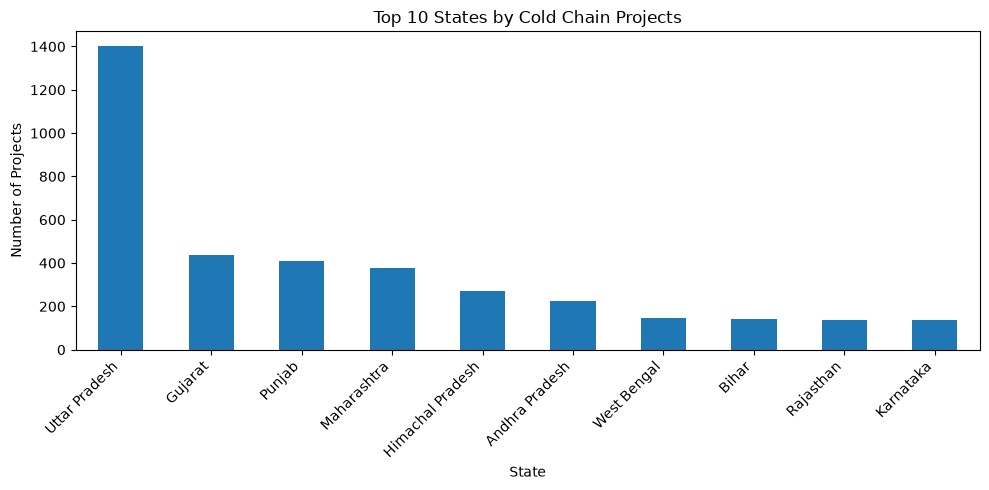

In [221]:
top_states.plot(kind="bar", figsize=(10, 5))
plt.title("Top 10 States by Cold Chain Projects")
plt.xlabel("State")
plt.ylabel("Number of Projects")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

<h3>The bar chart shows the top 10 states based on the number of unique cold-chain projects. Uttar Pradesh leads with 1,400 projects, followed by Gujarat with 437 and Punjab with 411 projects. Maharashtra and Himachal Pradesh also show significant project activity. This indicates that Uttar Pradesh has the highest concentration of recorded cold-chain projects among the states included in the dataset.</h3>

<h2>2. Number of Projects Across Subsidy Years</h2>

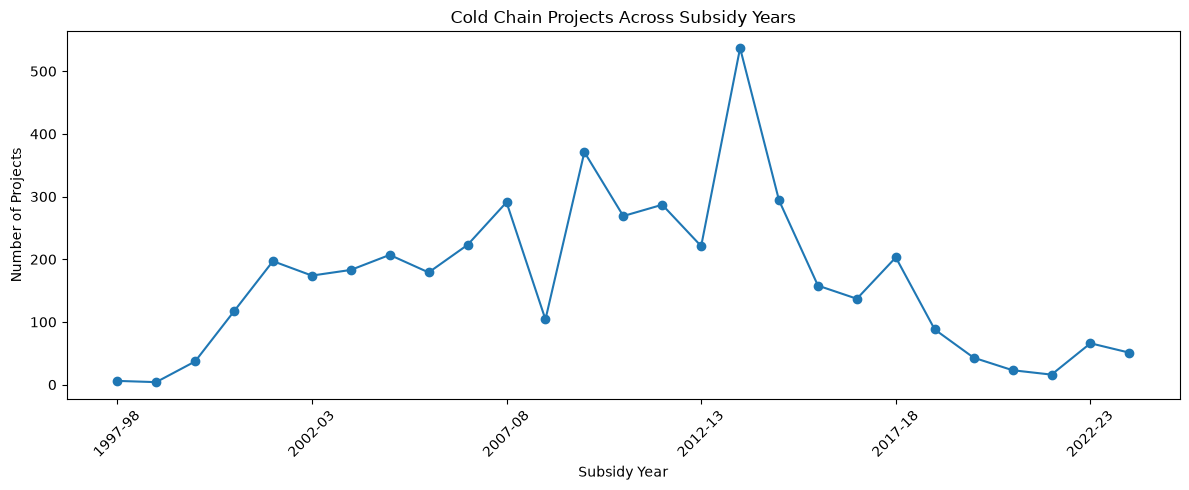

In [222]:
year_analysis.plot(
    kind="line",
    figsize=(12, 5),
    marker="o")
plt.title("Cold Chain Projects Across Subsidy Years")
plt.xlabel("Subsidy Year")
plt.ylabel("Number of Projects")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

<h3>The line chart represents the number of unique cold-chain projects across different subsidy years. The highest number of projects was recorded during 2013–14, with 537 projects. There was a gradual increase in project numbers during several earlier years, followed by fluctuations in later years. The number of projects decreased significantly after 2018–19, although some variation is visible in the most recent years. This chart helps identify changes in cold-chain infrastructure development over time.</h3>

<h2>3. Project Status Distribution</h2>

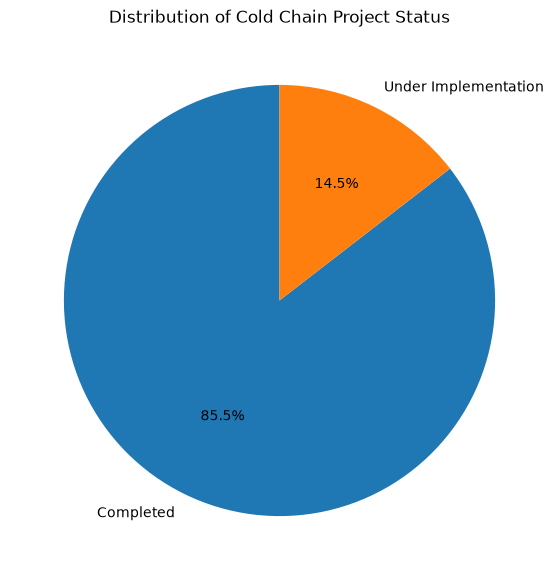

In [223]:
status_count = data["current_status"].value_counts()
plt.figure(figsize=(7, 7))
plt.pie(
    status_count,
    labels=status_count.index,
    autopct="%1.1f%%",
    startangle=90)
plt.title("Distribution of Cold Chain Project Status")
plt.show()

<h3>The pie chart shows the distribution of project records according to their current implementation status. Out of 5,040 records, 4,308 records (approximately 85.5%) are completed, while 732 records (approximately 14.5%) are under implementation. This indicates that the majority of recorded cold-chain infrastructure components have been completed. However, some projects are still under implementation and may require further monitoring.</h3>

<h2>4. Distribution of Cold Chain Component Categories</h2>

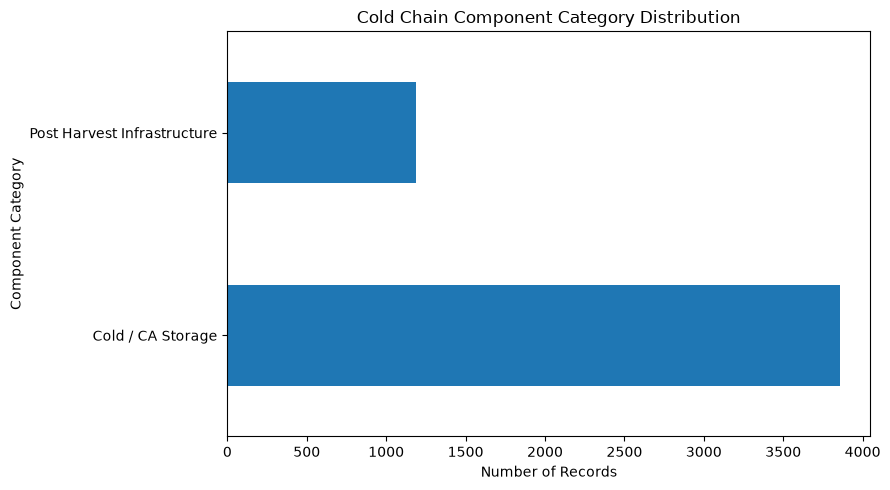

In [224]:
category_count = data["component_category"].value_counts()
category_count.plot(
    kind="barh",
    figsize=(9, 5))
plt.title("Cold Chain Component Category Distribution")
plt.xlabel("Number of Records")
plt.ylabel("Component Category")
plt.tight_layout()
plt.show()

<h3>The horizontal bar chart compares the two major cold-chain component categories. Cold / CA Storage has 3,855 records, while Post Harvest Infrastructure has 1,185 records. Cold / CA Storage represents the larger share of the dataset. This indicates that storage infrastructure is more heavily represented than post-harvest infrastructure in the recorded projects.</h3>

<h2>5. Project Status Comparison Across Top 10 States</h2>

(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]),
 [Text(0, 0, 'Uttar Pradesh'),
  Text(1, 0, 'Gujarat'),
  Text(2, 0, 'Punjab'),
  Text(3, 0, 'Maharashtra'),
  Text(4, 0, 'Himachal Pradesh'),
  Text(5, 0, 'Andhra Pradesh'),
  Text(6, 0, 'West Bengal'),
  Text(7, 0, 'Bihar'),
  Text(8, 0, 'Rajasthan'),
  Text(9, 0, 'Karnataka')])

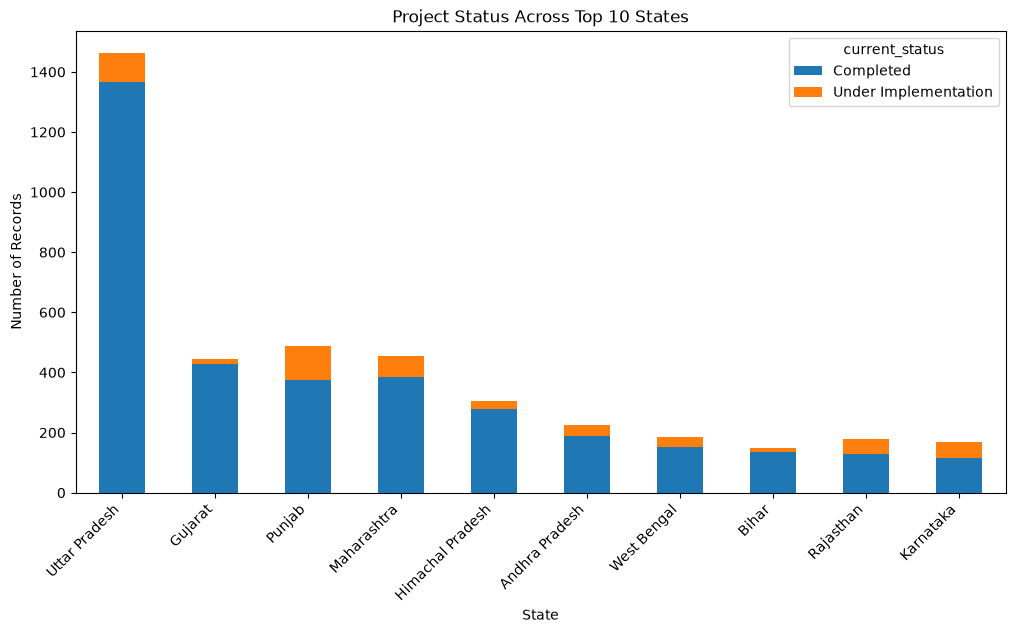

In [225]:
top_state_status.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6))
plt.title("Project Status Across Top 10 States")
plt.xlabel("State")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")

<h3>The stacked bar chart compares completed and under-implementation records across the top 10 states. Uttar Pradesh has the highest number of completed records, with 1,367, followed by Gujarat with 428 and Maharashtra with 385. Punjab has 112 records under implementation, which is the highest among these states. The chart helps identify differences in project implementation across states and highlights where more projects are still in progress.</h3>

<h2>6. Top 15 Districts by Number of Cold Chain Projects</h2>

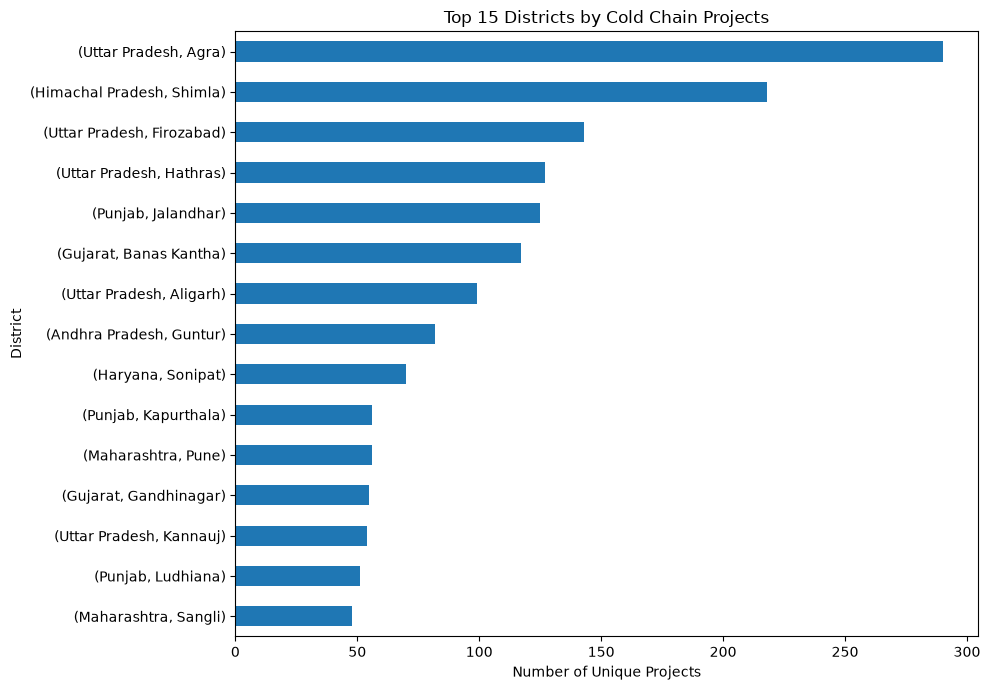

In [226]:
top_districts.plot(
    kind="barh",
    figsize=(10, 7))
plt.title("Top 15 Districts by Cold Chain Projects")
plt.xlabel("Number of Unique Projects")
plt.ylabel("District")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

<h3>The horizontal bar chart displays the top 15 districts based on their number of unique cold-chain projects. Agra in Uttar Pradesh leads with 290 projects, followed by Shimla in Himachal Pradesh with 218 projects. Firozabad and Hathras in Uttar Pradesh also have a significant number of projects. This indicates that certain districts have a higher concentration of cold-chain infrastructure development than others.
</h3>

<h2>7. Projects Associated with Different Agencies</h2>

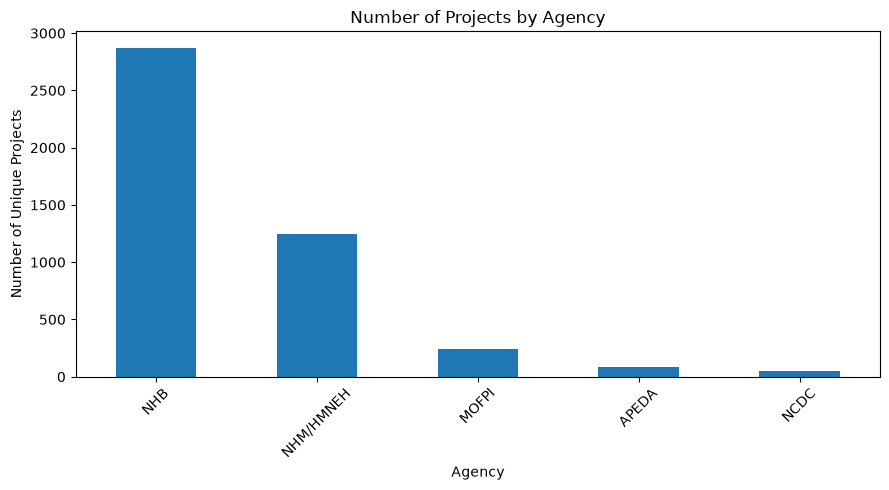

In [227]:
agency_data = agency_analysis.sort_values(ascending=False)
agency_data.plot(
    kind="bar",
    figsize=(9, 5))
plt.title("Number of Projects by Agency")
plt.xlabel("Agency")
plt.ylabel("Number of Unique Projects")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

<h3>The bar chart compares the number of unique cold-chain projects associated with different agencies. NHB has the highest representation with 2,872 projects, followed by NHM/HMNEH with 1,248 projects. MOFPI, APEDA and NCDC have comparatively fewer projects. This indicates that NHB and NHM/HMNEH account for the majority of agency-associated projects in the dataset.</h3>

<h2>8. Distribution of Cold Storage Capacity</h2>

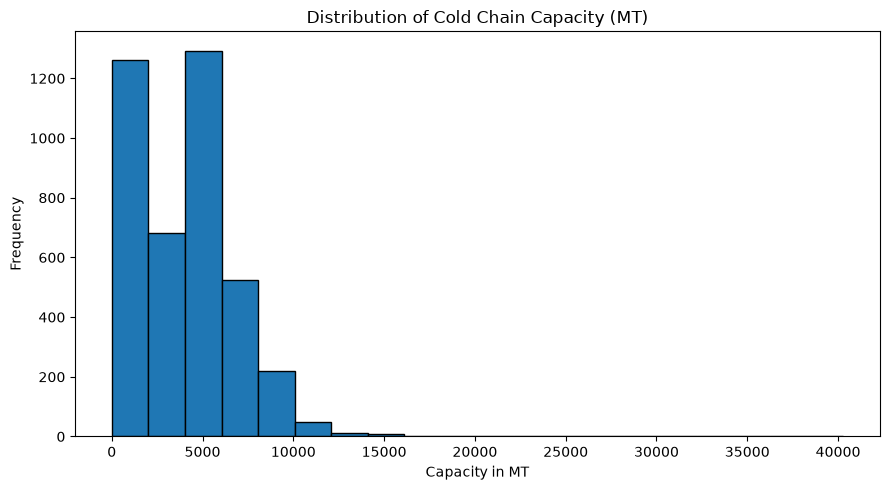

In [228]:
capacity_data = capacity_data.dropna(subset=["capacity"])
plt.figure(figsize=(9, 5))
plt.hist(
    capacity_data["capacity"],
    bins=20,
    edgecolor="black")
plt.title("Distribution of Cold Chain Capacity (MT)")
plt.xlabel("Capacity in MT")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

<h3>The histogram shows the distribution of cold-chain capacity values measured in metric tonnes (MT). The chart helps identify the frequency of different capacity ranges. It is useful for understanding whether most facilities have relatively small capacities or whether larger-capacity facilities are common. The distribution may be positively skewed because a smaller number of facilities have considerably higher capacities than the majority.</h3>

<h2>9. Capacity Comparison Between Different Components</h2>

In [229]:
selected_components = [
    "Cold Storage",
    "CA Storage",
    "Ripening Chamber"]

In [230]:
box_data = capacity_data[capacity_data["component"].isin(selected_components)]

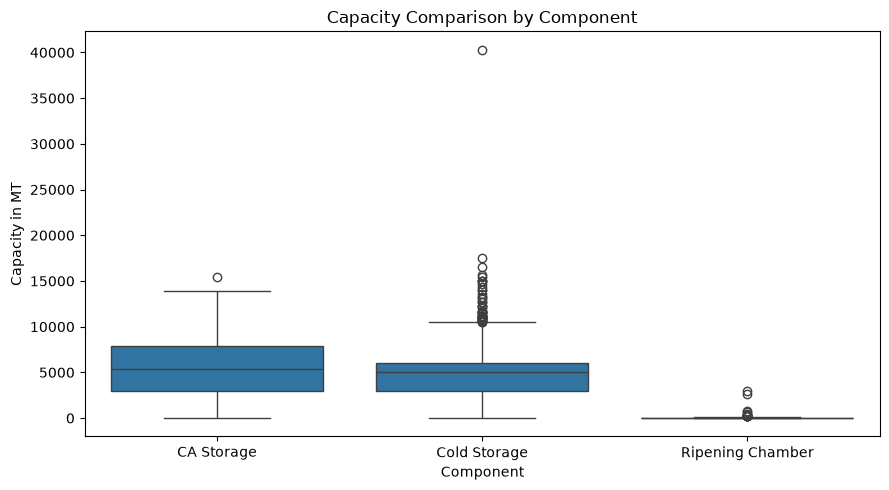

In [231]:
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=box_data,
    x="component",
    y="capacity")
plt.title("Capacity Comparison by Component")
plt.xlabel("Component")
plt.ylabel("Capacity in MT")
plt.tight_layout()
plt.show()

<h3>The box plot compares the capacity distribution of Cold Storage, CA Storage and Ripening Chamber facilities. It helps identify the median capacity, variation and extreme values for each component. Cold Storage and CA Storage generally operate at higher capacities than Ripening Chambers. The presence of outliers indicates that some facilities have significantly larger capacities than other facilities in the same component category.</h3>

<h2>10. Component Status Distribution by Category</h2>

In [232]:
component_status = pd.crosstab(
    data["component_category"],
    data["current_status"])

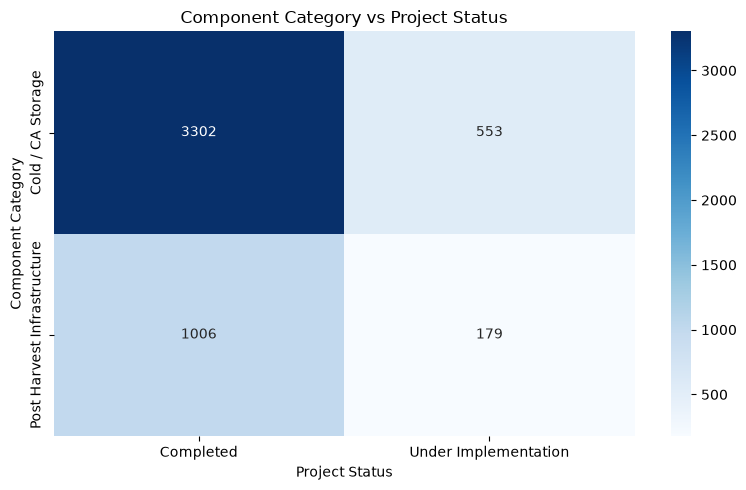

In [233]:
plt.figure(figsize=(8, 5))
sns.heatmap(
    component_status,
    annot=True,
    fmt="d",
    cmap="Blues")
plt.title("Component Category vs Project Status")
plt.xlabel("Project Status")
plt.ylabel("Component Category")
plt.tight_layout()
plt.show()

<h3>The heatmap compares the number of completed and under-implementation records across different component categories. Cold / CA Storage has 3,302 completed records and 553 records under implementation. Post Harvest Infrastructure has 1,006 completed records and 179 records under implementation. The heatmap shows that Cold / CA Storage has the highest number of records in both implementation categories. This indicates that storage infrastructure forms the largest part of the recorded cold-chain infrastructure.</h3>

<h1><u>Project Summary-Cold Chain Infrastructure Availability and Component Capacity in India</u></h1>

<h2> <b>1.</b> <u>OBJECTIVE AND GOAL</u> </h2>

<h3>The main objective of this project is to understand the geographical distribution of cold-chain projects, their implementation status, the contribution of different supporting agencies, changes in project development over subsidy years, and the availability of different infrastructure components.</h3>

<h3><B>Goal:</B>  To analyse the distribution, availability and capacity of cold-chain infrastructure across India and identify infrastructure gaps to support better development planning and decision-making.<h3>

<H2><B>2.</B><U>Data Cleaning and Preprocessing</U></H2>

<H3><B><U>Initial Dataset Assessment:</U></B> Inspected the dataset for missing values and duplicate records to ensure data quality and reliability</H3>

<H3><B><U>Missing Value Handling:</U></B></H3>

                        A.Identified missing information primarily in the supported_by column, which contained 2,081 missing values 
                        B.Other columns had comparatively fewer missing values.
                        C.Missing text values were filled with "Not Available" wherever appropriate.


<H3><B><U>Duplicate Record Check:</U> </B>Scanned for completely duplicated rows and found none; consequently, all 5,040 records were retained.</H3>

<H3><B><U>Data Type Conversions:</U></B></H3>
<H3>Converted numeric columns such as capacity and units into numeric data types to facilitate calculations and visualisations.
Retained the subsidy year as a text category since it represents a financial year rather than a continuous numerical measurement. </H3>

<H2><B>3.</B><U>KEY FINDINGS AND INSIGHTS</U></H2>

<H3><B><U>A. Geographical Distribution of Projects</U></B></H3>

<H3>The analysis showed that Uttar Pradesh has the highest number of unique cold-chain projects, with 1,400 projects. Gujarat followed with 437 projects, while Punjab recorded 411 projects.Other states with significant project numbers include Maharashtra, Himachal Pradesh, Andhra Pradesh and West Bengal.At the district level, Agra recorded the highest number of unique projects, with 290 projects, followed by Shimla with 218 projects. This shows that cold-chain infrastructure projects are distributed unevenly across different states and districts.</H3>

<H3><B><U>B. Project Implementation Status</U></B></H3>

<H3>The dataset contains 4,308 completed component records and 732 component records under implementation.
This means approximately 85.5% of the records are completed, while 14.5% are still under implementation.
The results indicate that most recorded infrastructure components have reached the completed stage, although some are still being developed.</H3>

<H3><B><U>C. Infrastructure Component Categories</U></B></H3>

<H3>The dataset mainly contains two major infrastructure categories:</H3>

<H3>Cold / CA Storage: 3,855 records.</H3>

<H3>Post Harvest Infrastructure: 1,185 records.</H3>

<H3>Cold / CA Storage represents the larger share of the dataset. This indicates that storage-related infrastructure is more heavily represented than post-harvest infrastructure in the available records.</H3>

<H3><B><U>D. Development Across Subsidy Years</U></B></H3>

<H3>The analysis of subsidy years helps identify changes in the number of cold-chain projects over time.</H3>

<H3>The highest number of unique projects was recorded during 2013–14, with 537 projects. The number of projects varied across different financial years, showing changes in the development and implementation of cold-chain infrastructure over time.</H3>

<H3>This analysis helps understand the historical pattern of project development.</H3>

<H3><B><U>E. Contribution of Different Agencies</U></B></H3>

<H3>The agency analysis shows that NHB has the highest number of associated unique projects, with 2,872 projects, followed by NHM/HMNEH with 1,248 projects.</H3>

<H3>Other agencies, including MOFPI, APEDA and NCDC, also appear in the dataset.</H3>

<H3>This indicates that multiple agencies are associated with the development and support of cold-chain infrastructure across India.</H3>

<H3><B><U>F. Infrastructure Capacity</U></B></H3>

<H3>Capacity analysis helps understand the recorded storage capacity of different cold-chain infrastructure components.</H3>

<H3>The dataset contains different capacity units, so capacity comparisons should be made only between records using the same measurement unit.</H3>

<H3>The histogram and box plot help examine capacity distribution, identify variations between infrastructure components and understand the presence of unusually high capacity values.</H3>

<H2><B>4.</B><U>STRATEGIC RECOMMENDATIONS</U></H2>

<H3><B><U>1. Focus on States with Lower Infrastructure Availability</U></B></H3>

<H3>Government authorities and relevant agencies should identify states and regions with lower cold-chain infrastructure availability and encourage the development of additional facilities based on agricultural production, storage demand and transportation requirements.</H3>

<H3><B><U>2. Strengthen Infrastructure Development in Underserved Districts</U></B></H3>

<H3>Infrastructure planning should focus on identifying underserved districts and evaluating their requirements. Developing suitable cold-storage and post-harvest facilities in these locations can help improve regional infrastructure coverage.</H3>

<H3><B><U>3. Improve Project Implementation and Monitoring</U></B></H3>

<H3>Regular monitoring systems should be strengthened to track ongoing projects, identify implementation delays and ensure timely completion. Agencies should maintain updated project status information to improve transparency and accountability.</H3>

<H3><B><U>4. Promote Balanced Infrastructure Development</U></B></H3>

<H3>Along with developing storage facilities, greater attention should be given to post-harvest infrastructure such as sorting, grading, packaging and processing facilities. A balanced infrastructure network can help improve the overall efficiency of the agricultural supply chain.</H3>

<H3><B><U>5. Encourage Infrastructure Development Based on Capacity Requirements</U></B></H3>

<H3>Future infrastructure investments should be planned according to local agricultural production, storage demand and the type of products handled. Both small-capacity and large-capacity facilities should be considered depending on regional requirements.</H3>